# Project work, part 2 - Data sources

## GitHub Repository and Streamlit App

https://github.com/sgkop/IND320-Innlevering-sgkop

https://ind320-innlevering1-sgkop.streamlit.app/

## Spark setup

In [2]:
import os
import sys

pyspark_path = r"C:\spark_temp\pyspark"
hadoop_path = r"C:\spark_temp\Hadoop\hadoop-3.3.1"
java_path = r"C:\Program Files\Microsoft\jdk-17.0.20.101-hotspot"

os.environ["SPARK_HOME"] = pyspark_path
os.environ["JAVA_HOME"] = java_path
os.environ["HADOOP_HOME"] = hadoop_path

os.environ["PATH"] = (
    os.environ["PATH"]
    + ";"
    + os.path.join(pyspark_path, "bin")
)

In [3]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("Test")
    .getOrCreate()
)

print(spark.version)

3.5.1


Spark setup
Spark 3.5.1 was configured using a local installation placed outside the OneDrive project directory. Java 17 and Hadoop 3.3.1 (winutils) were configured through environment variables before creating the Spark session.

## Spark-Cassandra Connection Test

In [5]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("SparkCassandra")
    .config(
        "spark.jars.packages",
        "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1"
    )
    .config("spark.cassandra.connection.host", "localhost")
    .config("spark.cassandra.connection.port", "9042")
    .getOrCreate()
)

print("Spark-Cassandra session created")

Spark-Cassandra session created


Apache Spark 3.5.1 was configured with the
DataStax Spark Cassandra Connector and connected
to a local Cassandra instance.

In [8]:
spark.range(5).show()

+---+
| id|
+---+
|  0|
|  1|
|  2|
|  3|
|  4|
+---+



## NVE Magasinstatistikk API

In [1]:
import requests
import pandas as pd

url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

response = requests.get(url)
response.raise_for_status()

magasin_data = response.json()

magasin_df = pd.DataFrame(magasin_data)

print(
    f"Dataset contains "
    f"{magasin_df.shape[0]} rows and "
    f"{magasin_df.shape[1]} columns."
)

magasin_df.head()

Dataset contains 14922 rows and 11 columns.


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


In [11]:
magasin_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14913 entries, 0 to 14912
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   dato_Id                   14913 non-null  str    
 1   omrType                   14913 non-null  str    
 2   omrnr                     14913 non-null  int64  
 3   iso_aar                   14913 non-null  int64  
 4   iso_uke                   14913 non-null  int64  
 5   fyllingsgrad              14913 non-null  float64
 6   kapasitet_TWh             14913 non-null  float64
 7   fylling_TWh               14913 non-null  float64
 8   neste_Publiseringsdato    14913 non-null  str    
 9   fyllingsgrad_forrige_uke  14913 non-null  float64
 10  endring_fyllingsgrad      14913 non-null  float64
dtypes: float64(5), int64(3), str(3)
memory usage: 1.7 MB


In [12]:
magasin_df["omrType"].unique()

<ArrowStringArray>
['EL', 'NO', 'VASS']
Length: 3, dtype: str

In [ ]:
magasin_df["dato_Id"] = pd.to_datetime(
    magasin_df["dato_Id"]
)

0   1995-09-03
1   2020-11-15
2   2011-08-28
3   1998-07-05
4   2011-03-27
Name: dato_Id, dtype: datetime64[us]

In [19]:
el1 = magasin_df[
    (magasin_df["omrType"] == "EL") &
    (magasin_df["omrnr"] == 1)
].copy()

el1 = el1.sort_values("dato_Id")

el1.head()

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
7882,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,0001-01-01T00:00:00,0.583705,0.033869
8225,1995-01-15,EL,1,1995,2,0.579205,6.003264,3.477117,0001-01-01T00:00:00,0.617574,-0.038369
8274,1995-01-22,EL,1,1995,3,0.546713,6.003264,3.282063,0001-01-01T00:00:00,0.579205,-0.032491
8135,1995-01-29,EL,1,1995,4,0.504545,6.003264,3.028916,0001-01-01T00:00:00,0.546713,-0.042168
7944,1995-02-05,EL,1,1995,5,0.465335,6.003264,2.793528,0001-01-01T00:00:00,0.504545,-0.039210


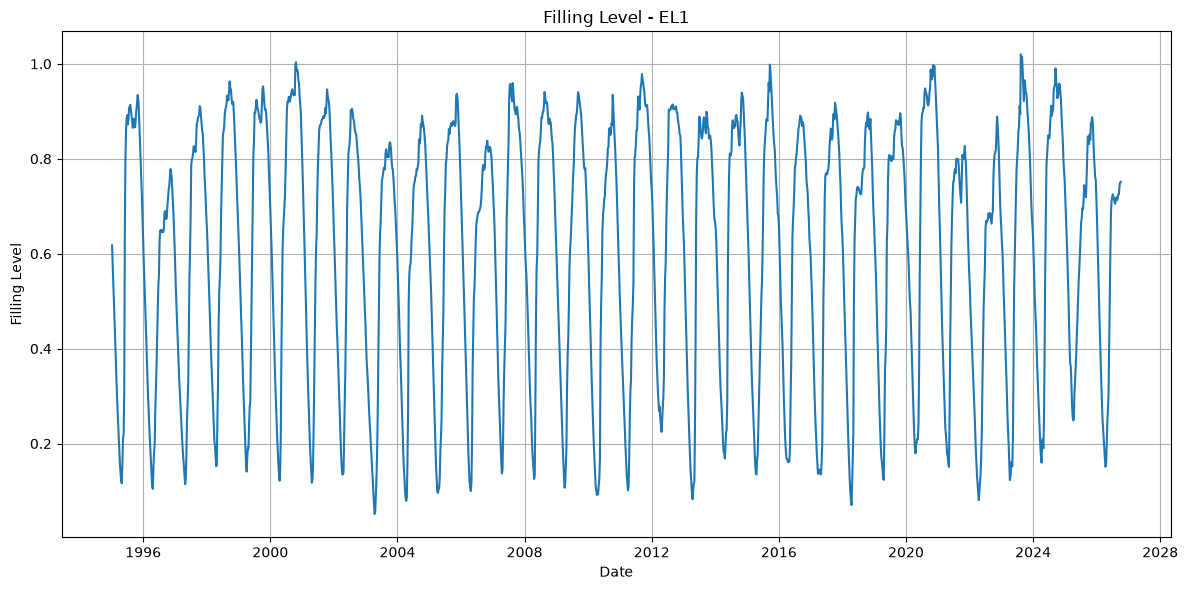

In [25]:
import matplotlib.pyplot as plt

# Filtrer og sorter på nytt
el1 = (
    magasin_df[
        (magasin_df["omrType"] == "EL") &
        (magasin_df["omrnr"] == 1)
    ]
    .copy()
)

el1["dato_Id"] = pd.to_datetime(el1["dato_Id"])

el1 = el1.sort_values("dato_Id")

plt.figure(figsize=(12,6))

plt.plot(
    el1["dato_Id"],
    el1["fyllingsgrad"]
)

plt.title("Filling Level - EL1")
plt.xlabel("Date")
plt.ylabel("Filling Level")
plt.grid(True)

plt.tight_layout()
plt.show()

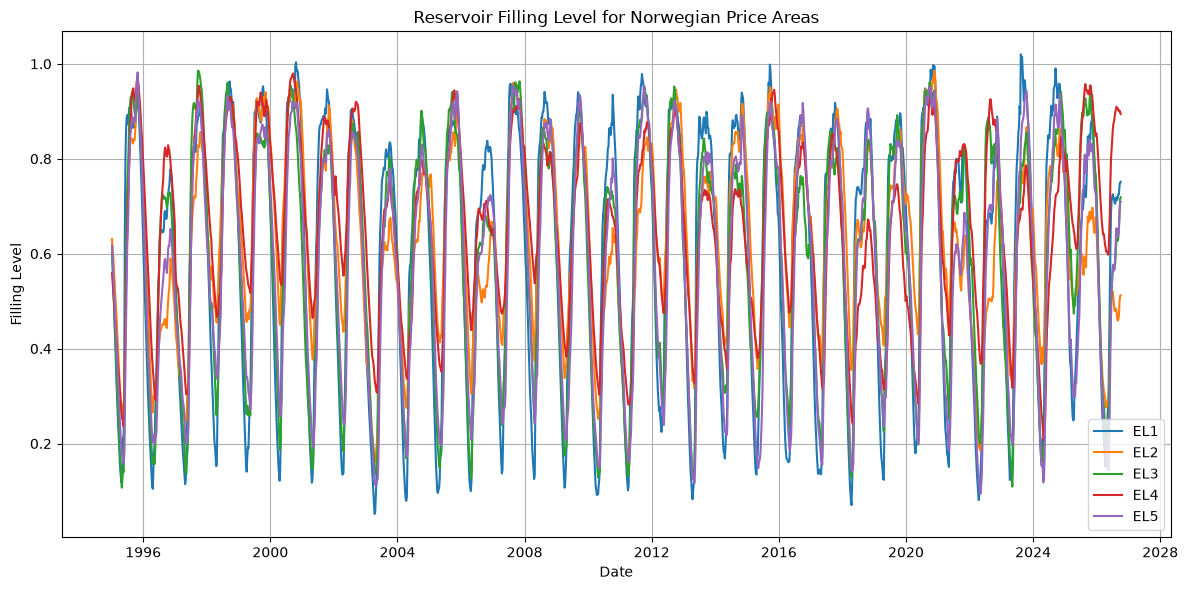

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for area in [1, 2, 3, 4, 5]:

    subset = (
        magasin_df[
            (magasin_df["omrType"] == "EL") &
            (magasin_df["omrnr"] == area)
        ]
        .copy()
    )

    subset["dato_Id"] = pd.to_datetime(subset["dato_Id"])
    subset = subset.sort_values("dato_Id")

    plt.plot(
        subset["dato_Id"],
        subset["fyllingsgrad"],
        label=f"EL{area}"
    )

plt.title("Reservoir Filling Level for Norwegian Price Areas")
plt.xlabel("Date")
plt.ylabel("Filling Level")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## MongoDB Connection test

In [ ]:
from pymongo import MongoClient

uri = "<MONGO_URI>"
client = MongoClient(uri)
try:
    client.admin.command("ping")
    print("Connected successfully")

except Exception as e:
    raise Exception(
        "The following error occurred: ", e)

Connected successfully


## ENTSO-E API

In [3]:
from entsoe import EntsoePandasClient

API_KEY = "<ENTSOE_API_KEY>"

client = EntsoePandasClient(api_key=API_KEY)

In [12]:
import pandas as pd

start = pd.Timestamp("2025-01-01", tz="Europe/Brussels")
end = pd.Timestamp("2025-01-08", tz="Europe/Brussels")

In [28]:
flows = client.query_crossborder_flows(
    country_code_from="NO_2",
    country_code_to="DK_1",
    start=start,
    end=end
)

flows.head()

2025-01-01 00:00:00+01:00    0.0
2025-01-01 01:00:00+01:00    0.0
2025-01-01 02:00:00+01:00    0.0
2025-01-01 03:00:00+01:00    0.0
2025-01-01 04:00:00+01:00    0.0
dtype: float64

In [29]:
len(flows)

28053

The query returned 28,053 hourly observations of cross-border electricity flows between NO2 and DK1 for 2025.

## Cross-Border Flow Data Processing

In [19]:
flows_df = flows.reset_index()

flows_df.columns = ["timestamp", "flow_mw"]

flows_df.head()

,timestamp,flow_mw
0,2025-01-01 00:00:00+01:00,0.0
1,2025-01-01 01:00:00+01:00,0.0
2,2025-01-01 02:00:00+01:00,0.0
3,2025-01-01 03:00:00+01:00,0.0
4,2025-01-01 04:00:00+01:00,0.0


In [21]:
flows_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 28053 entries, 0 to 28052
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype                      
---  ------     --------------  -----                      
 0   timestamp  28053 non-null  datetime64[us, Europe/Oslo]
 1   flow_mw    28053 non-null  float64                    
dtypes: datetime64[us, Europe/Oslo](1), float64(1)
memory usage: 438.5 KB


In [ ]:
flows_df["connection"] = "NO2-DK1"
flows_df["direction"] = "NO_to_DK"

The cross-border flow data were successfully retrieved from the ENTSO-E API and prepared in a Pandas DataFrame. The dataset contains timestamps, flow values, connection identifiers and flow direction. These data will be transferred to Spark and Cassandra in the next stage of the project

## Spark setup

In [37]:
import os
import sys

os.environ["SPARK_HOME"] = r"C:\spark_temp\pyspark"
os.environ["HADOOP_HOME"] = r"C:\spark_temp\Hadoop\hadoop-3.3.1"
os.environ["JAVA_HOME"] = r"C:\Program Files\Microsoft\jdk-17.0.20.101-hotspot"

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

In [38]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("IND320")
    .config(
        "spark.jars.packages",
        "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1"
    )
    .config("spark.cassandra.connection.host", "localhost")
    .config("spark.cassandra.connection.port", "9042")
    .getOrCreate()
)

In [21]:
flows_simple = flows_df.copy()

flows_simple["timestamp"] = (
    flows_simple["timestamp"]
    .dt.tz_localize(None)
)

## Cassandra storage

In [24]:
spark_flows_df = spark.createDataFrame(flows_simple)

spark_flows_df.show(5)

+-------------------+-------+----------+---------+
|          timestamp|flow_mw|connection|direction|
+-------------------+-------+----------+---------+
|2025-01-01 00:00:00|    0.0|   NO2-DK1| NO_to_DK|
|2025-01-01 01:00:00|    0.0|   NO2-DK1| NO_to_DK|
|2025-01-01 02:00:00|    0.0|   NO2-DK1| NO_to_DK|
|2025-01-01 03:00:00|    0.0|   NO2-DK1| NO_to_DK|
|2025-01-01 04:00:00|    0.0|   NO2-DK1| NO_to_DK|
+-------------------+-------+----------+---------+
only showing top 5 rows



In [25]:
spark_flows_df.write \
    .format("org.apache.spark.sql.cassandra") \
    .mode("append") \
    .options(
        table="crossborder_flows",
        keyspace="ind320"
    ) \
    .save()


In [26]:
df_from_cassandra = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(
        table="crossborder_flows",
        keyspace="ind320"
    )
    .load()
)

df_from_cassandra.show(5)

+----------+-------------------+---------+-------+
|connection|          timestamp|direction|flow_mw|
+----------+-------------------+---------+-------+
|   NO2-DK1|2025-01-01 00:00:00| NO_to_DK|    0.0|
|   NO2-DK1|2025-01-01 01:00:00| NO_to_DK|    0.0|
|   NO2-DK1|2025-01-01 02:00:00| NO_to_DK|    0.0|
|   NO2-DK1|2025-01-01 03:00:00| NO_to_DK|    0.0|
|   NO2-DK1|2025-01-01 04:00:00| NO_to_DK|    0.0|
+----------+-------------------+---------+-------+
only showing top 5 rows



In [27]:
selected_df = df_from_cassandra.select(
    "timestamp",
    "flow_mw",
    "connection",
    "direction"
)


In [30]:
selected_df.printSchema()

root
 |-- timestamp: timestamp (nullable = true)
 |-- flow_mw: double (nullable = true)
 |-- connection: string (nullable = false)
 |-- direction: string (nullable = true)



## Bidrectional Flow Processing

In [30]:
flows_back = client.query_crossborder_flows(
    country_code_from="DK_1",
    country_code_to="NO_2",
    start=start,
    end=end
)

In [31]:
flows_back_df = flows_back.reset_index()

flows_back_df.columns = ["timestamp", "flow_mw"]

flows_back_df["connection"] = "NO2-DK1"
flows_back_df["direction"] = "DK_to_NO"


In [32]:
flows_df["timestamp"] = flows_df["timestamp"].dt.tz_localize(None)

flows_back_df["timestamp"] = flows_back_df["timestamp"].dt.tz_localize(None)

## Combining Both Flow Directions

In [33]:
combined_df = pd.concat(
    [flows_simple, flows_back_df],
    ignore_index=True
)

In [34]:
combined_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 56106 entries, 0 to 56105
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   timestamp   56106 non-null  datetime64[us]
 1   flow_mw     56106 non-null  float64       
 2   connection  56106 non-null  str           
 3   direction   56106 non-null  str           
dtypes: datetime64[us](1), float64(1), str(2)
memory usage: 1.7 MB


In [35]:
combined_df.head()

,timestamp,flow_mw,connection,direction
0,2025-01-01 00:00:00,0.0,NO2-DK1,NO_to_DK
1,2025-01-01 01:00:00,0.0,NO2-DK1,NO_to_DK
2,2025-01-01 02:00:00,0.0,NO2-DK1,NO_to_DK
3,2025-01-01 03:00:00,0.0,NO2-DK1,NO_to_DK
4,2025-01-01 04:00:00,0.0,NO2-DK1,NO_to_DK


In [39]:
combined_spark_df = spark.createDataFrame(combined_df)

combined_spark_df.show(5)

+-------------------+-------+----------+---------+
|          timestamp|flow_mw|connection|direction|
+-------------------+-------+----------+---------+
|2025-01-01 00:00:00|    0.0|   NO2-DK1| NO_to_DK|
|2025-01-01 01:00:00|    0.0|   NO2-DK1| NO_to_DK|
|2025-01-01 02:00:00|    0.0|   NO2-DK1| NO_to_DK|
|2025-01-01 03:00:00|    0.0|   NO2-DK1| NO_to_DK|
|2025-01-01 04:00:00|    0.0|   NO2-DK1| NO_to_DK|
+-------------------+-------+----------+---------+
only showing top 5 rows



In [40]:
combined_spark_df.write \
    .format("org.apache.spark.sql.cassandra") \
    .mode("append") \
    .options(
        table="crossborder_flows",
        keyspace="ind320"
    ) \
    .save()

In [41]:
all_df = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(
        table="crossborder_flows",
        keyspace="ind320"
    )
    .load()
)

In [42]:
all_df.count()

28049

In [39]:
all_df.groupBy("direction").count().show()

+---------+-----+
|direction|count|
+---------+-----+
| NO_to_DK|  471|
| DK_to_NO|  273|
+---------+-----+



In [42]:
pie_df = (
    all_df.groupBy("direction")
    .sum("flow_mw")
    .toPandas()
)

pie_df

,direction,sum(flow_mw)
0,NO_to_DK,515475.77
1,DK_to_NO,43139.26


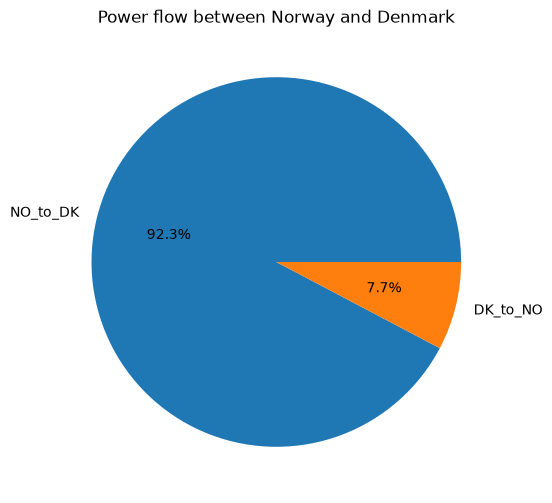

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))

plt.pie(
    pie_df["sum(flow_mw)"],
    labels=pie_df["direction"],
    autopct="%1.1f%%"
)

plt.title("Power flow between Norway and Denmark")
plt.show()

In [44]:
line_df = all_df.toPandas()

line_df = line_df.sort_values("timestamp")

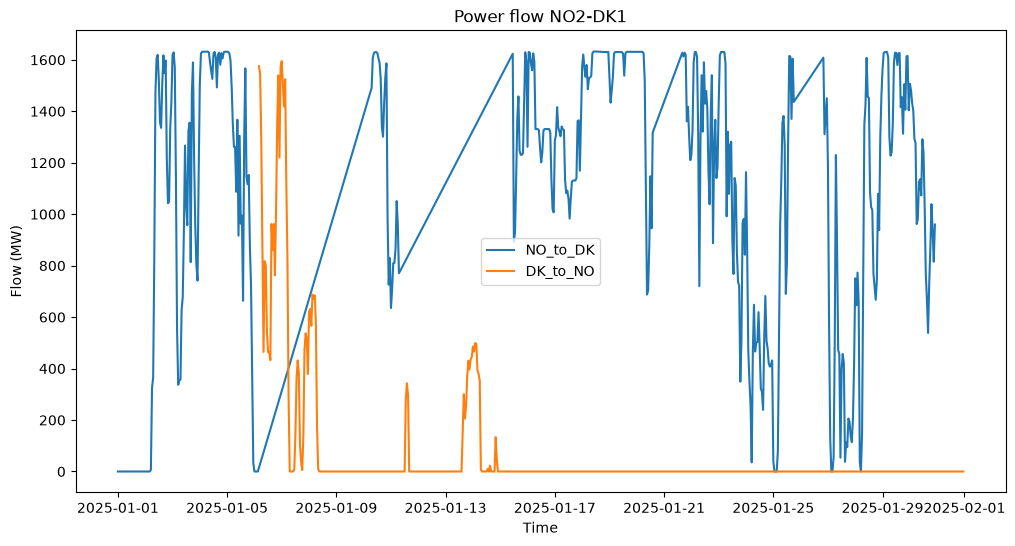

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

for direction in line_df["direction"].unique():
    subset = line_df[
        line_df["direction"] == direction
    ]

    plt.plot(
        subset["timestamp"],
        subset["flow_mw"],
        label=direction
    )

plt.legend()
plt.xlabel("Time")
plt.ylabel("Flow (MW)")
plt.title("Power flow NO2-DK1")
plt.show()

In [47]:
all_df

DataFrame[connection: string, timestamp: timestamp, direction: string, flow_mw: double]

In [45]:
# Spark -> Pandas
mongo_df = all_df.toPandas()

mongo_df.head()

,connection,timestamp,direction,flow_mw
0,NO2-DK1,2025-01-01 00:00:00,NO_to_DK,0.0
1,NO2-DK1,2025-01-01 01:00:00,NO_to_DK,0.0
2,NO2-DK1,2025-01-01 02:00:00,NO_to_DK,0.0
3,NO2-DK1,2025-01-01 03:00:00,NO_to_DK,0.0
4,NO2-DK1,2025-01-01 04:00:00,NO_to_DK,0.0


## MongoDB Storage

In [43]:
from pymongo import MongoClient

client = MongoClient(uri)

db = client["ind320"]
collection = db["crossborder_flows"]

In [44]:
collection.delete_many({})

In [46]:
mongo_df = all_df.toPandas()

mongo_df["timestamp"] = mongo_df["timestamp"].astype(str)

records = mongo_df.to_dict("records")

In [47]:
collection.insert_many(records)

InsertManyResult([ObjectId('6ad0f9c8ddc16db8e198a541'), ObjectId('6ad0f9c8ddc16db8e198a542'), ObjectId('6ad0f9c8ddc16db8e198a543'), ObjectId('6ad0f9c8ddc16db8e198a544'), ObjectId('6ad0f9c8ddc16db8e198a545'), ObjectId('6ad0f9c8ddc16db8e198a546'), ObjectId('6ad0f9c8ddc16db8e198a547'), ObjectId('6ad0f9c8ddc16db8e198a548'), ObjectId('6ad0f9c8ddc16db8e198a549'), ObjectId('6ad0f9c8ddc16db8e198a54a'), ObjectId('6ad0f9c8ddc16db8e198a54b'), ObjectId('6ad0f9c8ddc16db8e198a54c'), ObjectId('6ad0f9c8ddc16db8e198a54d'), ObjectId('6ad0f9c8ddc16db8e198a54e'), ObjectId('6ad0f9c8ddc16db8e198a54f'), ObjectId('6ad0f9c8ddc16db8e198a550'), ObjectId('6ad0f9c8ddc16db8e198a551'), ObjectId('6ad0f9c8ddc16db8e198a552'), ObjectId('6ad0f9c8ddc16db8e198a553'), ObjectId('6ad0f9c8ddc16db8e198a554'), ObjectId('6ad0f9c8ddc16db8e198a555'), ObjectId('6ad0f9c8ddc16db8e198a556'), ObjectId('6ad0f9c8ddc16db8e198a557'), ObjectId('6ad0f9c8ddc16db8e198a558'), ObjectId('6ad0f9c8ddc16db8e198a559'), ObjectId('6ad0f9c8ddc16db8e198a5

In [48]:
collection.count_documents({})

28049

In [49]:
mongo_df["timestamp"] = pd.to_datetime(mongo_df["timestamp"])

sorted(mongo_df["timestamp"].dt.month.unique())

[np.int32(1),
 np.int32(2),
 np.int32(3),
 np.int32(4),
 np.int32(5),
 np.int32(6),
 np.int32(7),
 np.int32(8),
 np.int32(9),
 np.int32(10),
 np.int32(11),
 np.int32(12)]

## Log

A significant part of the project work was spent configuring Apache Spark and establishing a working Spark-Cassandra environment. After encountering compatibility and startup issues, the project was migrated from the original Python environment to a clean Python 3.11 virtual environment. Spark also experienced problems related to the project's OneDrive location, which contained spaces and Norwegian characters in the file path. The issue was resolved by moving the Spark and Hadoop directories to a dedicated folder without special characters and updating the required environment variables. Following these changes, Spark started successfully, and a Spark session with the Cassandra connector was created.

The next step was integrating ENTSO-E cross-border electricity flow data into the data pipeline. Using the ENTSO-E API, hourly transmission data between the Norwegian bidding zone NO2 and the Danish bidding zone DK1 were retrieved. The solution was initially tested on one month of data before being expanded to cover the entire year 2025. Data from both directions (NO2→DK1 and DK1→NO2) were transformed into Pandas DataFrames, enriched with metadata describing connection and flow direction, and converted to Spark DataFrames.

The processed data were written to Cassandra and read back into Spark to verify that the storage process worked correctly. The data were then transferred to MongoDB Atlas, which served as the data source for the Streamlit application. During this phase, connection issues were encountered due to MongoDB Atlas network restrictions. After updating the allow list and verifying the connection, the data could be successfully inserted into MongoDB.

For the Streamlit application, the original reservoir pages were updated to retrieve data directly from the NVE API instead of local CSV files. A new cross-border flow dashboard was also developed using MongoDB as its data source. The dashboard includes a pie chart showing the annual distribution of power flows by direction and a line chart showing flow development over time. Streamlit components such as st.columns(), st.radio(), st.pills(), and st.expander() were used to create an interactive interface.

Following feedback from the previous assignment, the reservoir pages were redesigned to improve readability. Users can now select both area type (EL, NO or VASS) and area number, allowing plots and tables to focus on individual areas rather than displaying all areas simultaneously. The data table was also simplified by focusing on numeric variables and using LineChartColumn to provide compact trend visualizations. Overall, the project provided practical experience with APIs, Apache Spark, Cassandra, MongoDB Atlas and Streamlit, while demonstrating a complete data engineering workflow from data acquisition to interactive visualization.

## AI Usage

I acknowledge the use of Microsoft 365 Copilot (https://www.microsoft.com/copilot), based on the GPT-5 chat model, and Google Gemini during this project.

Microsoft 365 Copilot was used to discuss project structure, assist with debugging, explain data visualization choices, support the development of the Streamlit application, and review written documentation. Google Gemini was primarily used when troubleshooting Apache Spark configuration issues and helping identify the causes of startup and environment-related errors.

All code, visualizations, and written content were reviewed, tested, and adapted to reflect my own understanding and decisions. The final implementation, analysis, and design choices remain my own responsibility.